# 02 · O contrato v1: dois campos que salvam a contagem

**Objetivo:** medir quanto o payload v0 perde em três situações de chão de fábrica e ver, campo a campo, como o contrato v1 resolve cada uma.

## Antes de começar

- **Você precisa de:** o notebook 01.
- **Tempo:** 30 minutos.
- **Broker:** nenhum. Tudo roda com o nó ligado direto ao receptor, com relógio controlado, então os números são sempre os mesmos.

O texto completo do contrato está em [docs/protocol.md](../docs/protocol.md). Aqui vamos chegar nele pelos experimentos.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline

## 1. A regra do receptor

Do lado de quem recebe existe uma regra comum e razoável: **mensagem idêntica à outra aceita nos últimos 5 segundos é repetição, descarte**. Ela protege contra o broker ou uma bridge entregando a mesma mensagem duas vezes.

`LegacyPipeline` é essa regra em 15 linhas. O modelo foi conferido contra um backend de produção que aplica a mesma regra, com os mesmos números que você vai ver abaixo.

## 2. Experimento 1: máquina rápida

### Pare e preveja

Uma rotuladora faz **3 peças por segundo**. O nó v0 publica 30 peças em 10 segundos. Quantas o receptor conta: 30, 20, 10 ou 3?

In [2]:
from oeelab.lab import bench, counted, pulses

no, rx, relogio = bench("v0")
pulses(no, relogio, n=30, period_s=1/3)
print("peças feitas  :", 30)
print("peças contadas:", counted(rx))
print("descartadas como repetição:", rx.dropped)

peças feitas  : 30
peças contadas: 10
descartadas como repetição: 20


Uma por segundo sobrevive. As outras duas de cada segundo têm exatamente os mesmos bytes da primeira.

Agora o mesmo teste com o contrato v1:

In [3]:
no, rx, relogio = bench("v1")
pulses(no, relogio, n=30, period_s=1/3)
print("peças contadas:", counted(rx))
for _, p in no.sent[1:4]:
    print(json.dumps(p))

peças contadas: 30
{"v": 1, "seq": 0, "boot": "a1b2c3", "value": 1, "total": 1, "ts": "2026-11-10T09:00:00.000Z"}
{"v": 1, "seq": 1, "boot": "a1b2c3", "value": 1, "total": 2, "ts": "2026-11-10T09:00:00.333Z"}
{"v": 1, "seq": 2, "boot": "a1b2c3", "value": 1, "total": 3, "ts": "2026-11-10T09:00:00.666Z"}


Dois campos novos fazem o trabalho:

- **`seq`** sobe 1 a cada mensagem. Duas peças no mesmo milissegundo ainda são mensagens diferentes, e uma repetição de verdade tem o mesmo `seq`.
- **`total`** é a contagem desde o boot. Guarde esse campo, ele volta no experimento 3.

O gráfico abaixo repete o teste em várias velocidades.

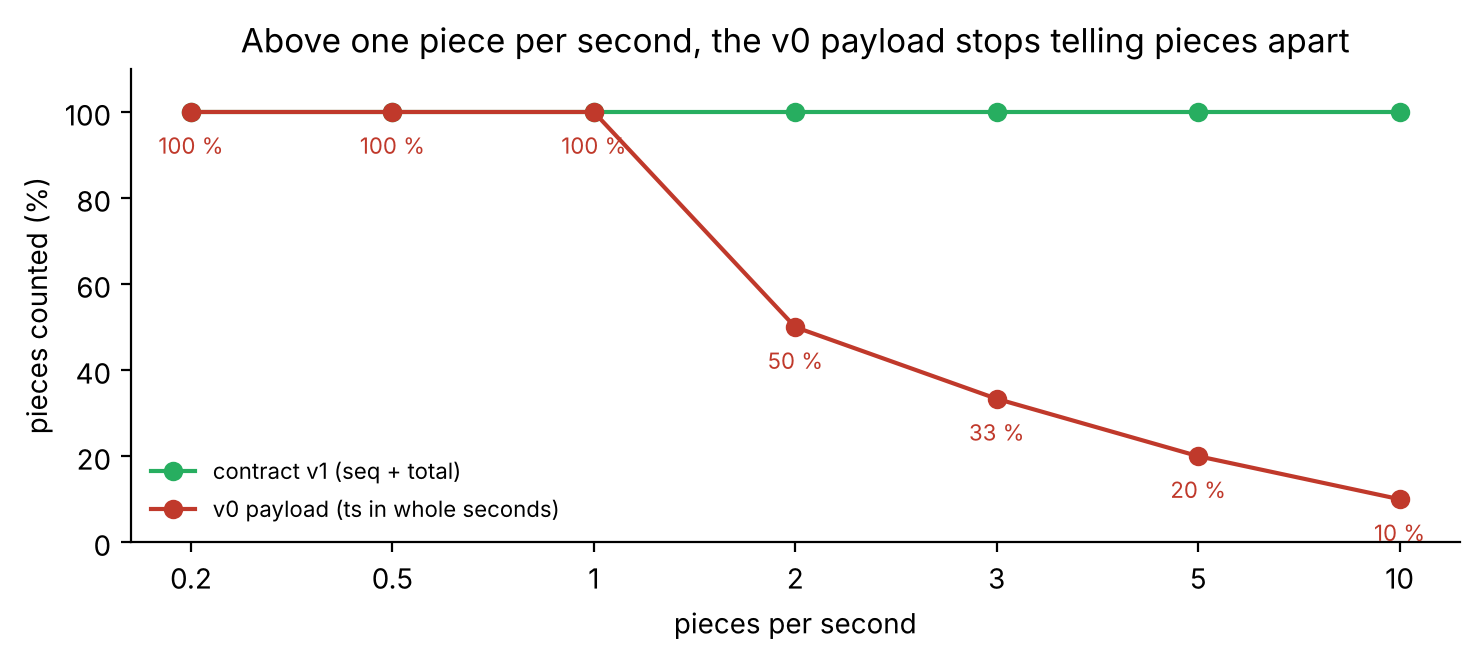

In [4]:
from oeelab import figures
figures.fast_pieces();

## 3. Experimento 2: nó sem relógio

O ESP32 não tem bateria de relógio. Se o servidor NTP não responder no boot (rede industrial sem saída para a internet é o caso típico), o relógio começa em 1970.

### Pare e preveja

Máquina lenta, uma peça a cada 2 segundos, 8 peças. Com o relógio em 1970, quantas o receptor conta?

In [5]:
no, rx, relogio = bench("v0", clock_synced=False)
pulses(no, relogio, n=8, period_s=2.0)
print("payload de toda peça:", json.dumps(no.sent[1][1]))
print("peças contadas      :", counted(rx), "de 8")

payload de toda peça: {"ts": "1970-01-01T00:00:00", "value": 1, "machine_id": "LABELER-01"}
peças contadas      : 3 de 8


Agora **toda** peça é idêntica, não só as do mesmo segundo. Passa uma a cada janela de 5 segundos.

A regra do v1 para tempo é curta: **`ts` é UTC correto ou não vai**. Sem relógio, o nó omite o campo e o receptor carimba com a própria hora.

In [6]:
no, rx, relogio = bench("v1", clock_synced=False)
pulses(no, relogio, n=8, period_s=2.0)
print("payload:", json.dumps(no.sent[1][1]))
print("peças contadas:", counted(rx), "de 8")

payload: {"v": 1, "seq": 0, "boot": "a1b2c3", "value": 1, "total": 1}
peças contadas: 8 de 8


## 4. Experimento 3: o Wi-Fi cai

Este é o caso que nenhuma regra no receptor resolve. Se a rede cai por alguns minutos, a máquina continua produzindo.

### Pare e preveja

No v0, cada peça é uma mensagem `value: 1`. A rede fica fora por 4 minutos e meio numa máquina de uma peça a cada 2,3 s. Quando a rede volta, o que o receptor sabe sobre as peças desse intervalo?

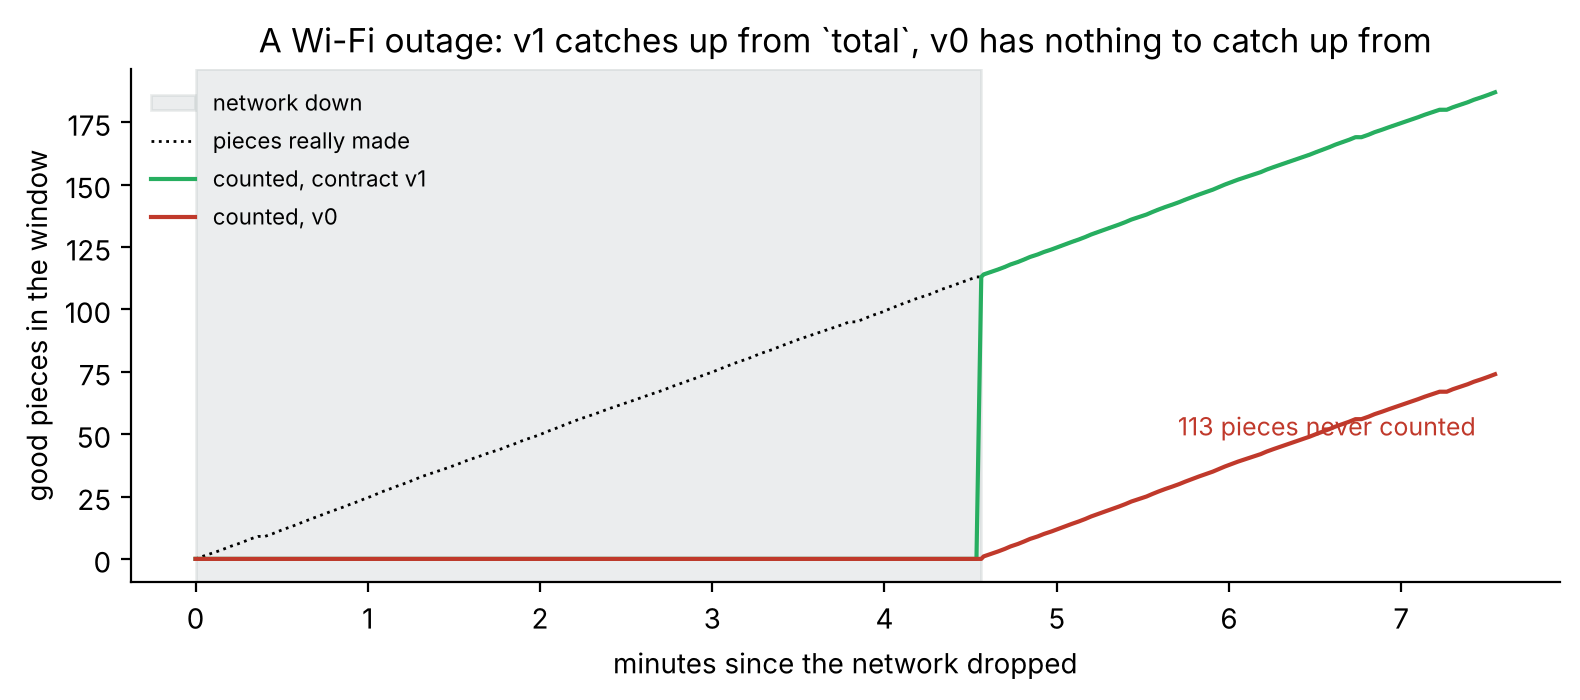

In [7]:
figures.outage();

No v0, nada. A peça que não foi enviada deixou de existir.

No v1 o nó continua contando com a rede fora. Quando volta, a primeira mensagem leva `value` com tudo o que ficou pendente e o `total` atualizado. O receptor soma a **diferença de `total`**, então não importa quantas mensagens se perderam no caminho.

Vamos ver isso por dentro, mensagem a mensagem:

In [8]:
from datetime import timedelta
from oeelab.lab import LABELER
from oeelab.scenario import SHIFT_START as t0

no, rx, relogio = bench("v1")
no.connect(t0)
def peca(s):
    relogio.now = t0 + timedelta(seconds=s); no.piece(relogio.now)

peca(1); peca(2)
no.link(False, t0 + timedelta(seconds=3))          # rede cai
for s in range(3, 13): peca(s)                      # 10 peças sem rede
relogio.now = t0 + timedelta(seconds=13)
no.link(True, relogio.now)                          # rede volta

for topico, p in no.sent:
    if "total" in p: print(f"seq {p['seq']:2d}  value {p['value']:2d}  total {p['total']:2d}")
print("\ncontadas:", counted(rx), "de 12")

seq  0  value  1  total  1
seq  1  value  1  total  2
seq  3  value 10  total 12

contadas: 12 de 12


## 5. Experimento 4: mensagens perdidas no caminho

O cliente MQTT usado no ESP32 só publica com QoS 0: enviou, esqueceu. Em Wi-Fi ruim, uma fração das mensagens some sem o nó saber. Vamos derrubar 20 % delas.

In [9]:
no, rx, relogio = bench("v1", loss=0.20, seed=3)
pulses(no, relogio, n=200, period_s=0.5)
print("mensagens publicadas:", len(no.sent))
print("buracos no seq      :", rx.rows("SELECT COALESCE(SUM(missing),0) n FROM gaps")[0]["n"], "mensagens faltando")
print("peças recuperadas pelo total:", rx.rows("SELECT COALESCE(SUM(recovered),0) n FROM pieces")[0]["n"])
print("peças contadas      :", counted(rx), "de 200")

mensagens publicadas: 201
buracos no seq      : 34 mensagens faltando
peças recuperadas pelo total: 34
peças contadas      : 200 de 200


O receptor **sabe** quantas mensagens perdeu (buracos no `seq`) e **recupera** as peças delas (diferença de `total`). Se a contagem ficar uma ou duas abaixo de 200, é porque a última mensagem também se perdeu: a recuperação só acontece quando chega a próxima. Como o contador é retido no broker, a próxima peça corrige.

## 6. O contrato inteiro em uma tabela

![Tópicos](../docs/img/topics.png)

| Campo | Para que serve | Problema que resolve |
|---|---|---|
| `v` | versão do contrato | receptor recusa o que não conhece |
| `seq` | número da mensagem | repetição de verdade tem o mesmo `seq`; buraco mostra perda |
| `boot` | identidade do boot | reinício do nó não parece contador andando para trás |
| `ts` | UTC com milissegundos, ou ausente | fim de 1970, de hora local e de `millis()` |
| `total` | contagem desde o boot | peça de mensagem perdida ou de rede fora é recuperada |

O contrato também é código. `validate` devolve a lista de problemas de um payload:

In [10]:
from oeelab.contract import validate

exemplos = {
  "v1 correto":            {"v":1,"seq":42,"boot":"a1b2c3","ts":"2026-11-10T09:00:02.480Z","value":1,"total":1532},
  "v0 full_signals":       {"ts":"2026-11-10T06:00:00","value":1,"machine_id":"FILLER-01"},
  "v0 webconfig":          {"label":"Peca boa","state":1,"ts":123456},
  "hora local sem Z":      {"v":1,"seq":42,"boot":"a1b2c3","ts":"2026-11-10T06:00:02","value":1,"total":1532},
  "total menor que value": {"v":1,"seq":42,"boot":"a1b2c3","value":5,"total":3},
}
for nome, p in exemplos.items():
    erros = validate("output-good", p)
    print(f"{nome:22s} {'OK' if not erros else 'RECUSADO: ' + erros[0]}")

v1 correto             OK
v0 full_signals        RECUSADO: ts: '2026-11-10T06:00:00' does not match '^\\d{4}-\\d{2}-\\d{2}T\\d{2}:\\d{2}:\\d{2}(\\.\\d{1,6})?Z$'
v0 webconfig           RECUSADO: ts: 123456 is not of type 'string'
hora local sem Z       RECUSADO: ts: '2026-11-10T06:00:02' does not match '^\\d{4}-\\d{2}-\\d{2}T\\d{2}:\\d{2}:\\d{2}(\\.\\d{1,6})?Z$'
total menor que value  RECUSADO: total: cannot be smaller than value


## Erros comuns

- **Resolver no receptor o que é defeito do payload.** Afrouxar a regra de repetição faz o v0 contar certo e volta a contar em dobro quando o broker repetir.
- **Aumentar a resolução do `ts` e parar aí.** Milissegundos reduzem a colisão e não resolvem rede fora nem mensagem perdida. `seq` e `total` resolvem.
- **Zerar o `total` a cada mensagem.** Ele só serve se for acumulado desde o boot.
- **Reusar o `boot` entre reinícios.** O receptor acharia que o contador andou para trás.
- **Confiar em QoS 1 para não perder peça.** QoS trata do trecho cliente e broker. Não ajuda se o nó nem estava conectado.

## Confira o que ficou

**1. Qual campo permite recuperar peças de mensagens que nunca chegaram?**

<details><summary>Ver resposta</summary>

`total`. O receptor soma a diferença entre o `total` recebido e o último que conhecia.

</details>

**2. Para que serve `seq` se o `total` já recupera as peças?**

<details><summary>Ver resposta</summary>

Para descartar repetições com certeza (mesmo `boot` e `seq`) e para saber que houve perda, o que é um indicador de saúde da rede. Vale também para sinais sem total, como `state`.

</details>

**3. O nó reinicia e o `total` volta a 2. Como o receptor sabe que não é erro?**

<details><summary>Ver resposta</summary>

O `boot` mudou. Boot novo zera a referência, e o receptor conta 2 em vez de uma diferença negativa.

</details>

**4. Por que o v1 manda omitir `ts` em vez de enviar o melhor palpite?**

<details><summary>Ver resposta</summary>

Porque um horário errado parece dado bom e contamina cálculos de duração. A ausência é honesta, e o receptor usa a própria hora.

</details>

**5. Qual perda o v1 ainda não resolve?**

<details><summary>Ver resposta</summary>

Peças contadas entre a última mensagem entregue e uma queda de energia, porque o `total` vive em RAM.

</details>

## Exercícios

1. Em `bench("v0")`, descubra a maior velocidade (peças por segundo) em que o v0 ainda conta 100 %. Explique o número.
2. Rode o experimento 4 com `loss=0.5`. A contagem continua certa? E o número de buracos?
3. Escreva um payload de `state` válido e um inválido e passe os dois por `validate("state", ...)`.
4. Leia a seção 9 de `docs/protocol.md` e proponha como seria o campo que falta para o `total` sobreviver a uma queda de energia.

## Glossário

- **Contrato:** acordo escrito e testável sobre tópicos e payloads.
- **Idempotente:** processar a mesma mensagem duas vezes dá o mesmo resultado que uma.
- **Contador acumulado:** valor que só cresce, do qual se tira a diferença.
- **QoS 0:** entrega no máximo uma vez, sem confirmação.
- **Dead letter:** lugar onde ficam as mensagens recusadas, com o motivo.

## Próximo passo

No notebook **03** um turno inteiro de três máquinas passa pelo coletor e vira OEE, e os firmwares antigos entram no contrato sem regravar nenhuma placa.